# Machine Learning Capstone Project

## Customer Segmentation using Online Retail Data

### Clustering

The objective of this project is to segment customers based on their purchasing behaviour using unsupervised machine learning techniques.

The Online Retail dataset contains transaction-level information such as invoice details, product information, quantity, price, customer identification, date, and country.

Customer-level behavioural features are created from the transaction data and used to perform clustering using K-Means and Agglomerative Hierarchical Clustering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

# 1. Dataset Path Verification

The location of the Online Retail dataset is checked before loading the data.

This ensures that the required dataset file is available and allows the dataset to be loaded correctly.

In [2]:
import zipfile
import os

ZIP_PATH = "online+retail.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall("data")

print("Files extracted:")
print(os.listdir("data"))

Files extracted:
['Online Retail.xlsx']


In [3]:
DATA_PATH = "data/Online Retail.xlsx"

print("Dataset file exists:", os.path.exists(DATA_PATH))

Dataset file exists: True


# 2. Loading the Dataset

The Online Retail dataset is loaded into a Pandas DataFrame.

The dataset contains transaction-level records of an online retail store. Each row represents a transaction containing information about the invoice, product, quantity purchased, price, customer, date, and country.

In [4]:
df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# 3. Dataset Overview

The structure of the dataset is examined by checking the number of rows, columns, column names, and data types.

This provides an initial understanding of the variables available for customer segmentation.

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows: 541909
Number of columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


# 4. Initial Data Inspection

The first and last few records are displayed to understand the structure and values of the transaction records.

In [6]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Last 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


# 5. Descriptive Statistics

Descriptive statistics are generated for the numerical variables to understand their ranges, central tendencies, and variability.

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 6. Missing Value Analysis

The dataset is checked for missing values in each column.

Missing values are particularly important in this dataset because CustomerID is required to construct customer-level features for segmentation.

In [8]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df)) * 100
})

display(missing_df)

,Missing Values,Missing Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


# 7. Duplicate Analysis

Duplicate transaction records are identified to determine whether repeated rows may affect the customer-level analysis.

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 5268


# 8. Data Cleaning

The dataset is cleaned before customer-level feature engineering.

Duplicate records are removed. Transactions without CustomerID are excluded because they cannot be assigned to a specific customer.

Transactions with non-positive quantities are excluded from the purchasing-behaviour analysis because they represent returns or cancellation-related records rather than completed purchases.

Rows with non-positive UnitPrice are also excluded because they do not represent positive-value purchases.

In [10]:
print("Original shape:", df.shape)

df = df.drop_duplicates()

df = df.dropna(subset=["CustomerID"])

df = df[df["Quantity"] > 0]

df = df[df["UnitPrice"] > 0]

print("Shape after cleaning:", df.shape)

Original shape: (541909, 8)
Shape after cleaning: (392692, 8)


# 9. Invoice Date Conversion

The InvoiceDate column is converted into datetime format.

This is required for calculating customer recency, which is one of the RFM features used for customer segmentation.

In [11]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Minimum Invoice Date:", df["InvoiceDate"].min())
print("Maximum Invoice Date:", df["InvoiceDate"].max())

Minimum Invoice Date: 2010-12-01 08:26:00
Maximum Invoice Date: 2011-12-09 12:50:00


# 10. Transaction Amount Feature

A TotalAmount feature is created by multiplying Quantity by UnitPrice.

This represents the monetary value of each transaction and will be used to calculate the customer's total monetary contribution.

In [12]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

display(df[["Quantity", "UnitPrice", "TotalAmount"]].head())

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


# 11. Customer-Level Feature Engineering

The original dataset contains transaction-level observations, whereas clustering is intended to identify groups of customers.

Therefore, transaction records are aggregated at the CustomerID level.

Three RFM features are created:

- Recency: number of days since the customer's most recent purchase.
- Frequency: number of unique invoices associated with the customer.
- Monetary: total amount spent by the customer.

These features provide a compact representation of customer purchasing behaviour.

In [13]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

display(rfm.head())

print("Number of customers:", len(rfm))

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


Number of customers: 4338


# 12. RFM Feature Statistics

The statistical properties of the customer-level RFM features are examined before clustering.

This helps identify differences in scale, skewness, and potential extreme customer behaviours.

In [14]:
rfm[["Recency", "Frequency", "Monetary"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.0000,51.00,142.0000,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


# 13. RFM Feature Distributions

The distributions of Recency, Frequency, and Monetary are visualised to examine the purchasing behaviour of customers.

The distributions are also inspected for skewness and extreme values before applying clustering algorithms.

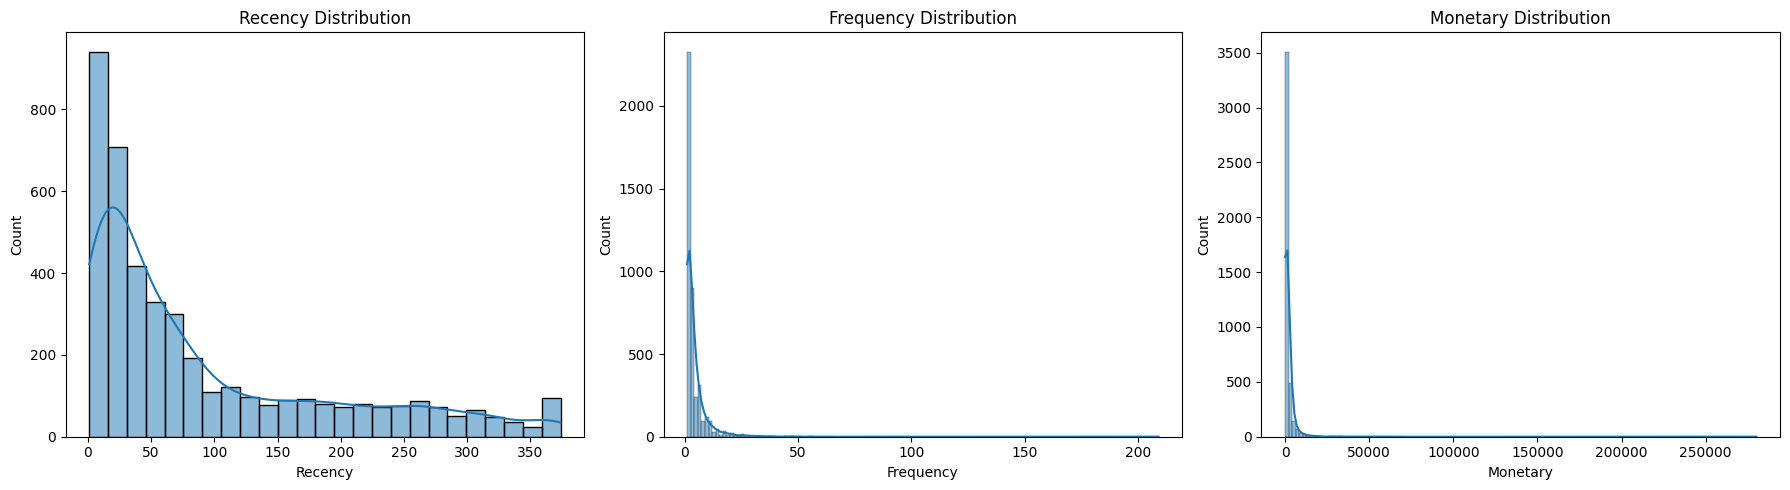

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm["Recency"], kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Recency")

sns.histplot(rfm["Frequency"], kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")
axes[1].set_xlabel("Frequency")

sns.histplot(rfm["Monetary"], kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")
axes[2].set_xlabel("Monetary")

plt.tight_layout()
plt.show()

### Observation

The RFM distributions show that customer purchasing behaviour is highly uneven across the dataset.

Recency is positively skewed, with a large number of customers having relatively low recency values and a smaller number of customers having much higher recency values.

Frequency is strongly right-skewed, with most customers making a relatively small number of purchases while a few customers make purchases much more frequently.

Monetary value is also highly right-skewed. Most customers have relatively low total spending, while a small number of customers have substantially higher monetary values.

The strong skewness and presence of extreme values indicate that the RFM features may be dominated by high-frequency and high-spending customers during distance-based clustering. Therefore, a logarithmic transformation followed by feature scaling will be applied before clustering.

# 14. RFM Transformation

The RFM features are examined for skewness and transformed using log1p where appropriate.

Log transformation reduces the influence of highly skewed values and extreme customer behaviour, which can otherwise have a strong effect on distance-based clustering algorithms.

In [16]:
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_log = np.log1p(rfm_features)

display(rfm_log.describe().T)

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,3.830734,1.340261,0.693147,2.944439,3.951244,4.962845,5.926926
Frequency,4338.0,1.345582,0.683104,0.693147,0.693147,1.098612,1.791759,5.347108
Monetary,4338.0,6.588562,1.258438,1.558145,5.728418,6.506636,7.415535,12.543284


# 15. Feature Scaling

The transformed RFM features are standardised using StandardScaler.

Scaling is important because clustering algorithms based on distance can be influenced by variables with larger numerical ranges.

The scaled features are used as input to both K-Means and Agglomerative Hierarchical Clustering.

In [17]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(rfm_log)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)

display(X_scaled.head())

,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.707716
1,-2.038734,1.074425,1.414903
2,0.373104,0.386304,0.720024
3,-0.623086,-0.955214,0.702287
4,1.424558,-0.955214,-0.614514


# 16. K-Means Clustering

K-Means clustering partitions customers into a predefined number of clusters by assigning each customer to the nearest cluster centroid.

The appropriate number of clusters is investigated using the Elbow Method before fitting the final K-Means model.

# 17. Elbow Method

The Elbow Method is used to examine the within-cluster sum of squares, represented by K-Means inertia, for different values of k.

The point where the reduction in inertia begins to slow down provides an indication of a suitable number of clusters.

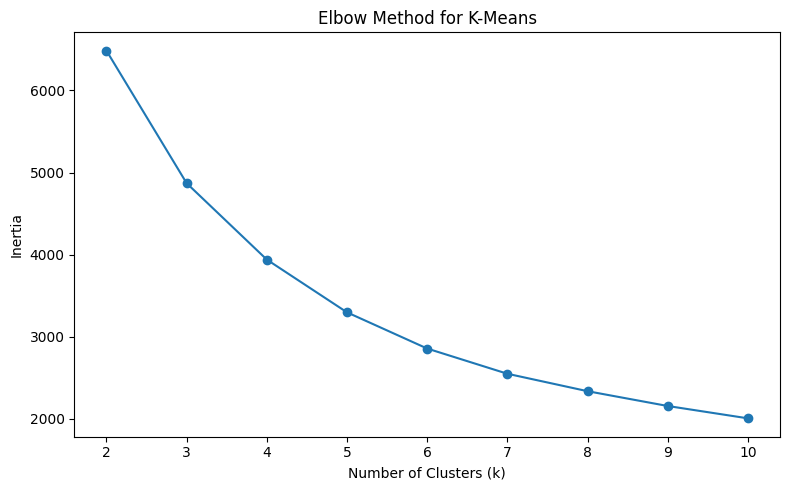

In [18]:
inertias = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(k_values, inertias, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.tight_layout()
plt.show()

### Observation

The Elbow Method shows a substantial reduction in inertia as the number of clusters increases from k = 2 to k = 5. After k = 5, the reduction in inertia becomes considerably more gradual.

Therefore, k = 5 is selected as the initial number of clusters for K-Means.

# 18. K-Means Model

The K-Means algorithm is fitted using the number of clusters selected from the Elbow analysis.

In [19]:
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

rfm["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed.")
print("Number of clusters:", optimal_k)

K-Means clustering completed.
Number of clusters: 5


# 19. Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering starts with individual observations and progressively merges similar observations or clusters.

The resulting hierarchy can be visualised using a dendrogram. The clustering results are then compared with K-Means using the required evaluation metrics.

In [20]:
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

rfm["Hierarchical_Cluster"] = hierarchical_labels

print("Agglomerative clustering completed.")

Agglomerative clustering completed.


# 20. Dendrogram

A dendrogram is used to visualise the hierarchy of cluster formation in Agglomerative Hierarchical Clustering.

The vertical distance represents the dissimilarity at which clusters are merged.

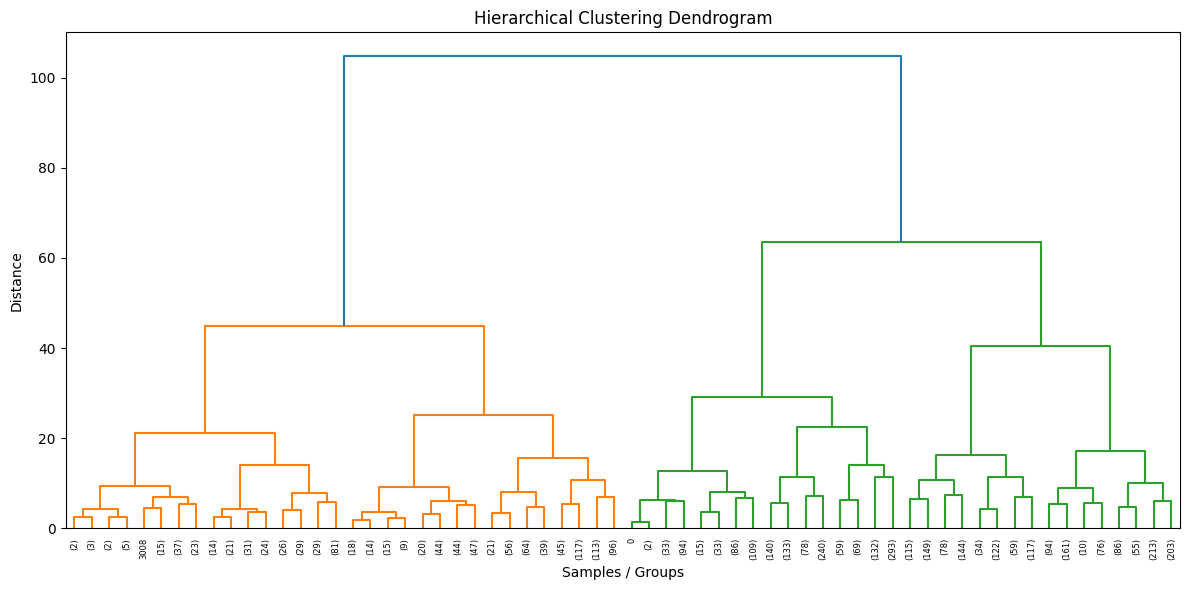

In [21]:
linkage_matrix = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="level",
    p=5
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples / Groups")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()

# 21. Clustering Evaluation

The clustering algorithms are evaluated using three mandatory internal clustering metrics:

- Silhouette Score
- Davies-Bouldin Index
- Calinski-Harabasz Index

These metrics evaluate the quality of the clusters without using a target label during model fitting.

In [22]:
def evaluate_clustering(X, labels):
    return {
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }

kmeans_metrics = evaluate_clustering(
    X_scaled,
    kmeans_labels
)

hierarchical_metrics = evaluate_clustering(
    X_scaled,
    hierarchical_labels
)

# 22. Clustering Comparison

The performance of K-Means and Agglomerative Hierarchical Clustering is compared using the three required clustering evaluation metrics.

In [23]:
comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        **kmeans_metrics
    },
    {
        "Algorithm": "Agglomerative Hierarchical",
        **hierarchical_metrics
    }
])

display(comparison)

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.316200,0.987779,3192.977083
1,Agglomerative Hierarchical,0.280524,1.030797,2754.948040


# 23. PCA Cluster Visualisation

Principal Component Analysis (PCA) is used to reduce the scaled RFM feature space to two dimensions for visualisation.

The resulting two-dimensional representation is used to visualise the cluster assignments produced by each algorithm.

In [24]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.75078634 0.18786648]
Total explained variance: 0.9386528181989527


## K-Means PCA Visualisation

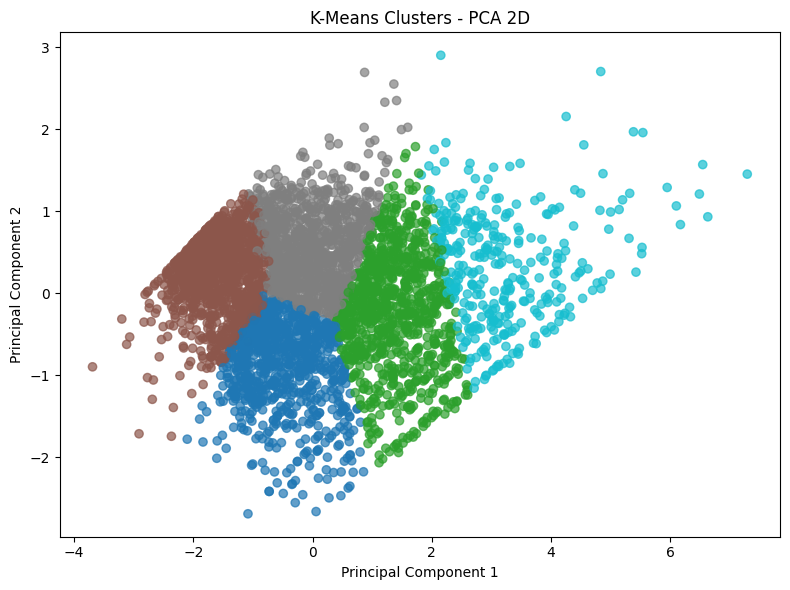

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters - PCA 2D")

plt.tight_layout()
plt.show()

### Observation

The PCA visualization shows five distinct K-Means customer clusters in the reduced two-dimensional feature space.

The clusters show relatively clear separation, particularly along Principal Component 1. Some overlap is visible around the central region, especially between neighbouring clusters, but the overall structure indicates that the K-Means algorithm has identified distinct groups of customers based on their RFM purchasing behaviour.

The first two principal components explain approximately 93.86% of the total variance, indicating that the two-dimensional PCA representation retains most of the information contained in the original RFM feature space.

The clustering quality is further supported by the Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.

## Agglomerative Clustering PCA Visualisation

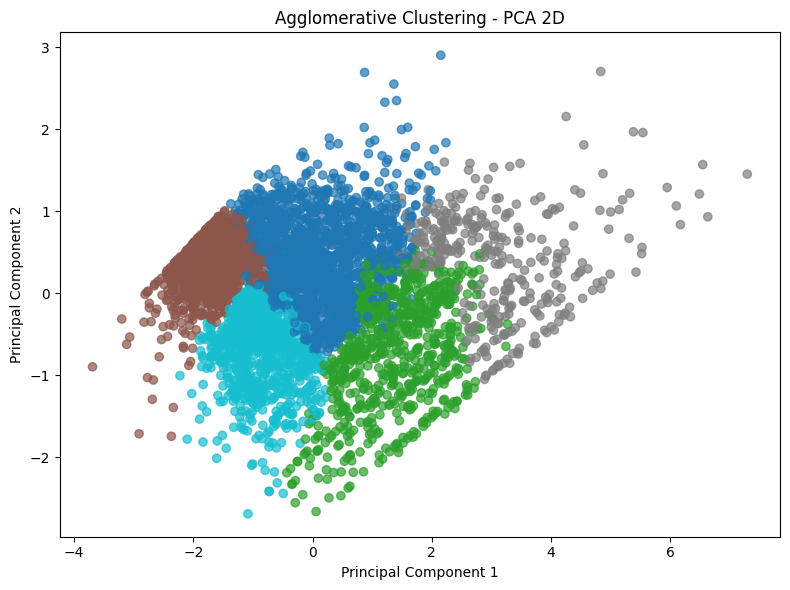

In [26]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering - PCA 2D")

plt.tight_layout()
plt.show()

### Observation

The PCA visualization shows the five clusters produced by Agglomerative Hierarchical Clustering.

The clusters occupy different regions of the reduced feature space, although noticeable overlap is present between some neighbouring clusters, particularly around the central region.

The visualization provides a two-dimensional representation of the hierarchical clustering result. The quantitative clustering metrics are used alongside this visualization to compare the two algorithms.

# 26. t-SNE Visualisation

t-SNE is used to create a two-dimensional representation of the customer feature space.

Unlike PCA, t-SNE focuses on preserving local neighbourhood relationships and is used here to provide an additional visual perspective on the selected clustering solution.

In [27]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_scaled)

# 27. K-Means t-SNE Visualisation

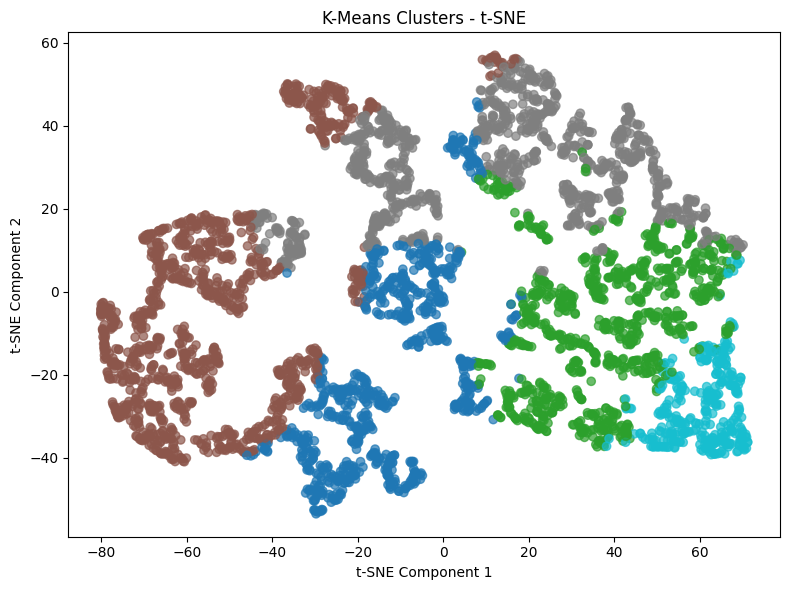

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Clusters - t-SNE")

plt.tight_layout()
plt.show()

### Observation

The t-SNE visualization shows the five K-Means clusters distributed into several distinct regions in the two-dimensional embedding.

The clusters exhibit noticeable separation in several areas, although some overlap is present between neighbouring groups. Compared with PCA, t-SNE provides a different view of the local structure of the customer feature space.

The t-SNE plot is used as a visualisation tool and does not directly determine the clustering quality. The quantitative clustering metrics are therefore used as the primary basis for comparing the algorithms.

# 28. Customer Cluster Profiling

The average RFM values of the K-Means clusters are calculated to understand the purchasing behaviour represented by each cluster.

This allows the numerical clusters to be interpreted in terms of customer behaviour.

In [29]:
cluster_profile = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

display(cluster_profile)

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,26.988010,1.641487,389.578189
1,18.514925,5.839019,2179.404542
2,208.350703,1.210918,277.219711
3,103.663065,3.132613,1452.360946
4,12.162242,20.746313,13877.159735


### Cluster Interpretation

The cluster profiles reveal distinct customer purchasing behaviours based on the RFM features.

- Cluster 0 represents relatively recent customers with low purchase frequency and low monetary value.
- Cluster 1 represents relatively recent customers with moderate purchase frequency and higher monetary value.
- Cluster 2 represents customers with high recency and very low frequency and monetary value, indicating a relatively inactive and low-value segment.
- Cluster 3 represents customers with moderate purchase frequency and monetary value but higher recency than Clusters 0 and 1.
- Cluster 4 represents the most recent, most frequent, and highest-spending customers, making it the strongest high-value customer segment in the dataset.

Overall, the RFM profiles demonstrate that the K-Means clusters correspond to meaningful differences in customer purchasing behaviour.

# 29. Final Clustering Comparison

K-Means and Agglomerative Hierarchical Clustering were compared using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.

K-Means achieved a higher Silhouette Score and Calinski-Harabasz Index, while also achieving a lower Davies-Bouldin Index than Agglomerative Hierarchical Clustering.

Therefore, K-Means provides the stronger overall clustering solution for the Online Retail customer segmentation task based on the three evaluation metrics.

In [30]:
display(comparison)

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.316200,0.987779,3192.977083
1,Agglomerative Hierarchical,0.280524,1.030797,2754.948040


### Observation

K-Means achieves a higher Silhouette Score (0.3162) than Agglomerative Hierarchical Clustering (0.2805), indicating better cluster separation and cohesion.

K-Means also achieves a lower Davies-Bouldin Index (0.9878) compared with Agglomerative Hierarchical Clustering (1.0308), indicating better-defined and less overlapping clusters according to this metric.

The Calinski-Harabasz Index is higher for K-Means (3192.98) than for Agglomerative Hierarchical Clustering (2754.95), indicating better separation relative to within-cluster dispersion.

Therefore, K-Means provides the stronger overall clustering solution for this dataset based on all three evaluation metrics.

# 30. Clustering Conclusion

The Online Retail dataset was analysed using an end-to-end customer segmentation workflow.

The transaction-level data was cleaned and aggregated at the customer level using Recency, Frequency, and Monetary features. Log transformation and feature scaling were applied to reduce the effect of skewness and differences in feature magnitude.

K-Means and Agglomerative Hierarchical Clustering were implemented using five clusters. The Elbow Method was used to identify an appropriate value of k for K-Means, while a dendrogram was used to examine the hierarchical clustering structure.

The clustering algorithms were evaluated using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. K-Means achieved better results across all three metrics, with a Silhouette Score of 0.3162, Davies-Bouldin Index of 0.9878, and Calinski-Harabasz Index of 3192.98.

PCA and t-SNE were used to visualise the resulting customer segments. The first two PCA components explained approximately 93.86% of the total variance.

The final K-Means clusters revealed distinct customer segments ranging from relatively inactive and low-value customers to highly frequent, recent, and high-spending customers. Cluster 4 represented the strongest high-value customer segment based on its RFM profile.

Overall, K-Means was selected as the preferred clustering approach for this customer segmentation task.